# Merger-tree schematic: a low-resolution MW-mass tree

Three panels for a schematic, all from one low-resolution SatGen tree of a $10^{12}\,M_\odot$ host, keeping only the **10 most massive subhalos alive at $z=0$**:

1. **3D realization at $z=0$**: each subhalo is a sphere of radius equal to its tidal radius, at its host-centric position. The host $R_{\rm vir}$ is a red dashed circle.
2. **Full merger tree**: every branch in the tree, plotted against cosmic time.
3. **Graph of the $z=0$ snapshot**: the host plus the 10 subhalos, each with an arrow to its immediate parent.

**One colour scheme throughout.** Colour is set by subhalo order $k$, using the `Set1` order map from `jsm_visualize` (`plt.cm.get_cmap('Set1', MAX_LEVELS + 1)`): host ($k=0$) red, $k=1$ blue, $k=2$ purple.

**One numbering throughout.** The host is `0`. The 10 subhalos are numbered `1–10` by their $z=0$ bound mass, most massive first. The same number labels the same subhalo in every figure.

Tree indices below are `Tree_Reader` indices, i.e. *after* it drops the dead row 1 of the raw SatGen arrays.

In [1]:
import os, sys
import warnings; warnings.simplefilter('ignore')

SATGEN = '/Users/jsmonzon/Research/SatGen'
sys.path.insert(0, f'{SATGEN}/src')
sys.path.insert(0, f'{SATGEN}/mcmc/src')

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.lines import Line2D

import config as cfg
import jsm_SubGen_MW_analog as treegen   # Parkinson+08 tree generation (TreeGen_Sub)
import jsm_SubEvo_masscut as subevo      # subhalo evolution (Green profiles, King62 tidal radius)
import jsm_visualize as jv

plt.style.use(f'{SATGEN}/notebooks/paper1/paper.mplstyle')
%matplotlib inline

## Parameters

* `lg_psi_res`: tree mass resolution, $\log_{10}(M_{\rm res}/M_0)$. At $10^{-2.5}$ the tree has about 55 branches; at $10^{-2}$ it has about 20, but only around 5–9 subhalos survive to $z=0$ and none of them are $k=2$.
* `seed`: fixes the random draws in both TreeGen and SubEvo, so the tree can be reproduced. I scanned seeds 0–19 at $10^{-2.5}$. Only seeds 12 and 13 put two $k=2$ subhalos in the top 10. Seed 12 is the cleaner of the two: an LMC-like $k=1$ subhalo ($2.4\times10^{11}\,M_\odot$) fell in at $z\approx0.04$ and brought two $k=2$ satellites with it.

In [2]:
lgM0       = 12.0     # log10 host mass at z=0 [Msun]
lg_psi_res = -2.5     # log10 tree mass resolution, Mres / M0
seed       = 12
N_top      = 10       # number of subhalos to show
overwrite  = False    # regrow + re-evolve even if the files already exist

workdir = f'{SATGEN}/notebooks/visualization/schematic'
treedir = f'{workdir}/trees/'
figdir  = f'{workdir}/figures/'
os.makedirs(treedir, exist_ok=True)
os.makedirs(figdir, exist_ok=True)

## Grow and evolve the tree

The `loop` functions are the same ones the batch scripts run. Only their module-level settings are overridden here. One catch: the batch scripts run in separate processes, but here they share one kernel, so `cfg.Mres` has to be reset after TreeGen (see the comment in the cell). `treegen.loop` calls `np.random.seed()` with no argument (fresh entropy) at the start of every tree, so that call is temporarily pinned to `seed`, which makes the run reproducible.

In [3]:
tag      = f'MW_lgres{lg_psi_res}_s{seed}'
raw_file = f'{treedir}tree_{tag}.npz'
evo_file = f'{treedir}tree_{tag}_evo.npz'

if overwrite or not os.path.exists(evo_file):
    for f in (raw_file, evo_file):
        if os.path.exists(f): os.remove(f)

    # --- TreeGen_Sub
    treegen.final_path = treedir
    treegen.lgM0 = lgM0
    treegen.lgMres = lgM0 + lg_psi_res
    cfg.psi_res = 10**lg_psi_res
    _seed = np.random.seed
    np.random.seed = lambda *args: _seed(seed)
    try:
        treegen.loop(tag)          # writes tree_{tag}.npz
    finally:
        np.random.seed = _seed
    # treegen.loop leaves cfg.Mres at the tree resolution; ev.msub would then use it as a hard
    # floor on every subhalo mass. Reset it to the SubEvo default (None -> floor at phi_res * m_acc).
    cfg.Mres = None

    # --- SubEvo (release events draw random numbers too)
    np.random.seed(seed)
    subevo.loop(raw_file)          # writes tree_{tag}_evo.npz

print(evo_file)

/Users/jsmonzon/Research/SatGen/notebooks/visualization/schematic/trees/tree_MW_lgres-2.5_s12_evo.npz


In [4]:
tree = jv.Tree_Vis(file=evo_file, verbose=False, mass_threshold=0.0)

alive = np.where(tree.orbit_mask[:, 0])[0]
top   = alive[np.argsort(tree.mass[alive, 0])[::-1]][:N_top]   # tree indices, most massive first
label = {0: 0} | {ind: n + 1 for n, ind in enumerate(top)}      # tree index -> schematic number

print(f"host: M = {tree.mass[0, 0]:.2e} Msun, Rvir = {tree.VirialRadius[0, 0]:.0f} kpc")
print(f"{tree.Nhalo - 1} branches, {alive.size} alive at z=0, "
      f"{(tree.disrupt_index[1:] > 0).sum()} disrupted\n")
print(' #  ind  k  parent  log m(z=0)  log m_acc  z_acc   r [kpc]')
for ind in top:
    p = tree.ParentID[ind, 0]
    print(f"{label[ind]:2d} {ind:4d} {tree.order[ind, 0]:2d} {label.get(p, f'({p})'):>7}"
          f" {np.log10(tree.mass[ind, 0]):10.2f} {np.log10(tree.acc_mass[ind]):10.2f}"
          f" {tree.acc_redshift[ind]:6.2f} {tree.rmags_stitched[ind, 0]:9.0f}")

host: M = 1.00e+12 Msun, Rvir = 259 kpc
56 branches, 24 alive at z=0, 32 disrupted

 #  ind  k  parent  log m(z=0)  log m_acc  z_acc   r [kpc]
 1    1  1       0      11.38      11.40   0.04       187
 2   10  1       0      10.42      10.63   0.98       112
 3   26  2       1      10.29      10.34   0.46       370
 4    6  1       0      10.19      10.34   0.52       435
 5   11  1       0      10.10      10.34   1.25       181
 6   25  2       1       9.98      10.45   0.19       202
 7    5  1       0       9.87      10.25   0.40       214
 8    4  1       0       9.80      10.13   0.30       252
 9    7  1       0       9.59       9.88   0.71       372
10    3  1       0       9.56       9.81   0.29       238


### Colour scheme

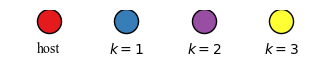

In [5]:
ORDER_CMAP = plt.cm.get_cmap('Set1', tree.MAX_LEVELS + 1)   # identical to Tree_Vis.plot_subhalo_projection
order_color = lambda k: ORDER_CMAP(int(k))
ORDER_NAME = {0: 'host', 1: '$k=1$', 2: '$k=2$', 3: '$k=3$'}

fig, ax = plt.subplots(figsize=(4, 0.6))
for k in range(4):
    ax.scatter(k, 0, s=300, color=order_color(k), ec='k')
    ax.text(k, -0.9, ORDER_NAME[k], ha='center', va='top')
ax.set_xlim(-0.5, 3.5); ax.set_ylim(-1.5, 0.5); ax.axis('off')
plt.show()

## Figure 1: 3D realization at $z=0$

Each of the 10 subhalos is drawn as a sphere at its host-centric position (`cartesian_stitched`), with radius equal to its tidal radius from `Tree_Vis.compute_tidal_radius` (King62, in the potential of the immediate parent, capped at $r_{\rm vir,acc}$). Spheres are coloured by order and labelled with the schematic numbers.

The host $R_{\rm vir}$ is a red dashed circle. By default (`rvir_plane = 'view'`) it is drawn in the plane perpendicular to the line of sight. With the orthographic projection used here, that circle is exactly the outline of the $R_{\rm vir}$ sphere from any `elev`/`azim`. Set `rvir_plane = 'xy'` to draw it in the $z=0$ plane instead.

Spheres can be 0.5–2 $R_{\rm vir}$ from the centre. `half` sets the half-width of the box in units of $R_{\rm vir}$.

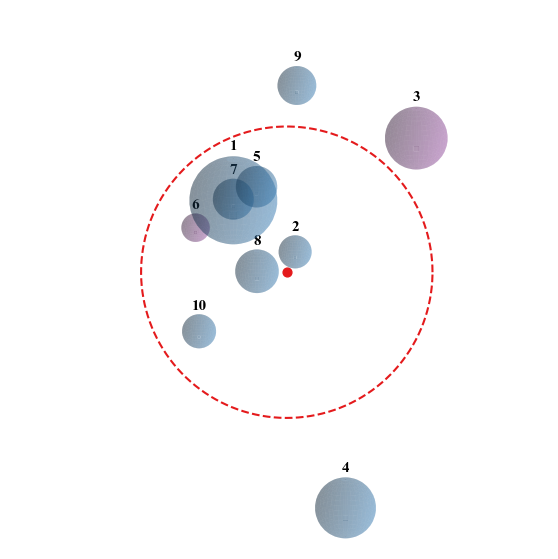

In [ ]:
elev, azim  = 20, -60     # camera angles [deg]
half        = 1.1         # half-width of the box, in units of Rvir
rvir_plane  = 'view'      # 'view' (outline of the Rvir sphere) or 'xy'
sphere_alpha = 0.
show_axes   = True

sel = np.zeros(tree.Nhalo, dtype=bool); sel[top] = True
rt   = tree.compute_tidal_radius(iz=0, mask=sel)
xyz  = tree.cartesian_stitched[:, 0, :3]
rvir = tree.VirialRadius[0, 0]

u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 40), np.linspace(0, np.pi, 20))
unit_sphere = np.array([np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v)])

fig = plt.figure(figsize=(7, 7))
ax  = fig.add_subplot(projection='3d', proj_type='ortho')
ax.view_init(elev=elev, azim=azim)

for ind in top[np.argsort(rt[top])[::-1]]:   # largest first
    X, Y, Z = xyz[ind, :, None, None] + rt[ind] * unit_sphere
    ax.plot_surface(X, Y, Z, color=order_color(tree.order[ind, 0]), alpha=sphere_alpha,
                    linewidth=0, antialiased=True, shade=True)
    ax.text(*(xyz[ind] + rt[ind] * np.array([0.0, 0.0, 1.15])), str(label[ind]),
            ha='center', va='bottom', fontsize=11, fontweight='bold', zorder=10)

# host: centre + Rvir circle
ax.scatter(0, 0, 0, color=order_color(0), s=40, depthshade=False)
phi = np.linspace(0, 2 * np.pi, 300)
if rvir_plane == 'view':
    e, a = np.radians(elev), np.radians(azim)
    n  = np.array([np.cos(e) * np.cos(a), np.cos(e) * np.sin(a), np.sin(e)])   # line of sight
    e1 = np.cross([0, 0, 1], n); e1 /= np.linalg.norm(e1)
    e2 = np.cross(n, e1)
else:
    e1, e2 = np.array([1, 0, 0]), np.array([0, 1, 0])
ring = rvir * (np.outer(np.cos(phi), e1) + np.outer(np.sin(phi), e2))
ax.plot(*ring.T, color=order_color(0), ls='--', lw=1.5, zorder=20)

L = half * rvir
ax.set_xlim(-L, L); ax.set_ylim(-L, L); ax.set_zlim(-L, L)
ax.set_box_aspect((1, 1, 1))
if show_axes:
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_visible(False)
else:
    ax.set_axis_off()

handles = [Line2D([], [], marker='o', ls='', ms=9, mfc=order_color(k), mec='none', alpha=sphere_alpha + 0.2,
                  label=ORDER_NAME[k]) for k in sorted(set(tree.order[top, 0]))]
handles.append(Line2D([], [], color=order_color(0), ls='--', lw=1.5, label=f'$R_{{\\rm vir}}$ = {rvir:.0f} kpc'))
# ax.legend(handles=handles, loc='upper right', fontsize=10, frameon=False)

fig.savefig(f'{figdir}fig1_3d_realization_z0.pdf', bbox_inches='tight')
plt.show()

## Figure 2: full merger tree

This follows Arborist's `Tree.draw` (`Arborist/src/arborist/core/tree.py`), which is itself an adaptation of `Tree_Vis.plot_acc_tree`, ported here to the SatGen `Tree_Vis` arrays:

* each branch is a node, linked to the branch it was accreted onto (`acc_ParentID`) by a light-grey edge;
* **y** is $\log_{10}(1+z_{\rm acc})$, with the host at $y=0$ at the bottom, so time runs downward as in the reference schematic;
* **x** is a depth-first leaf ordering, so it has no physical meaning and only keeps branches apart. Siblings are ordered earliest accretion first, so a late infall (e.g. #1) is not drawn on top of its parent;
* **node size** $\propto \log(m_{\rm acc}/M_0)$;
* **colour** is the order at accretion, using the same `Set1` map as the other figures;
* **disrupted** branches are faded (`disrupted_alpha`), and the top 10 carry their number.

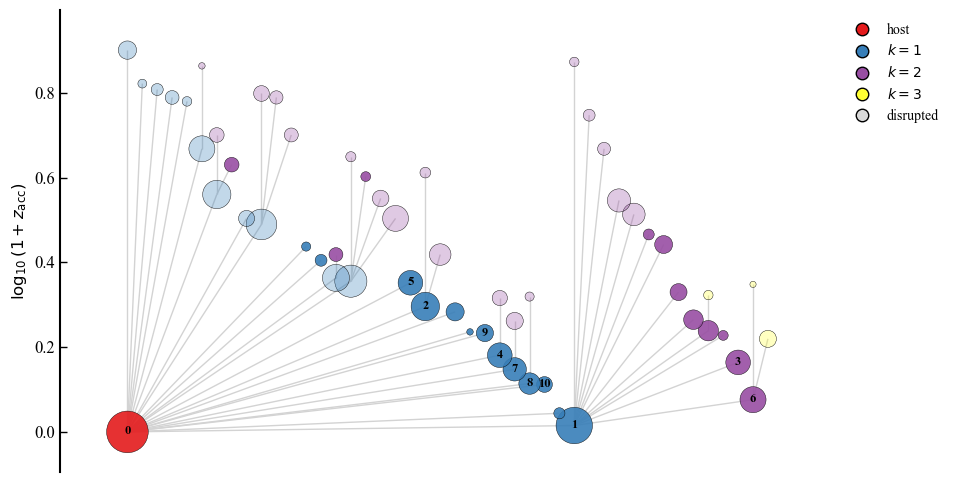

In [7]:
disrupted_alpha = 0.3
min_size, max_size = 20.0, 900.0
top_s = set(top)

G = nx.DiGraph()
G.add_node(0)
for ind in range(1, tree.Nhalo):
    G.add_edge(int(tree.acc_ParentID[ind]), ind)

# depth-first leaf ordering (Arborist Tree.draw / Tree_Vis.plot_acc_tree)
pos, x_counter = {}, [0]
def assign_pos(node, x):
    pos[node] = (x, 0.0 if node == 0 else np.log10(1.0 + tree.acc_redshift[node]))
    kids = sorted(G.successors(node), key=lambda c: -tree.acc_redshift[c])   # earliest accretion first
    if not kids:
        x_counter[0] += 5
    for c in kids:
        assign_pos(c, x_counter[0])
assign_pos(0, x=0)

nodes = list(G.nodes)
log_frac = np.log10(np.clip(np.array([tree.acc_mass[n] for n in nodes]) / tree.target_mass, 1e-6, None))
sizes = min_size + (log_frac - log_frac.min()) / np.ptp(log_frac) * (max_size - min_size)

def node_rgba(n):
    r, g, b, _ = order_color(0 if n == 0 else tree.acc_order[n])
    disrupted = n != 0 and tree.disrupt_index[n] > 0
    return (r, g, b, disrupted_alpha if disrupted else 0.9)

fig, ax = plt.subplots(figsize=(10, 6))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color='lightgrey', arrows=False)
nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodes, node_size=sizes,
                       node_color=[node_rgba(n) for n in nodes], edgecolors='k', linewidths=0.3)
nx.draw_networkx_labels(G, pos, labels={n: label[n] for n in nodes if n in label}, ax=ax,
                        font_size=9, font_weight='bold', font_family=plt.rcParams['font.family'])

ax.set_ylabel(r'$\log_{10}(1+z_{\rm acc})$')
ax.tick_params(left=True, labelleft=True, right=False, bottom=False, labelbottom=False, top=False)
for side in ('top', 'right', 'bottom'):
    ax.spines[side].set_visible(False)

orders = sorted({0} | {int(tree.acc_order[n]) for n in nodes if n != 0})
handles = [Line2D([], [], marker='o', ls='', ms=9, mfc=order_color(k), mec='k', label=ORDER_NAME[k]) for k in orders]
handles.append(Line2D([], [], marker='o', ls='', ms=9, mfc=(0.5, 0.5, 0.5, disrupted_alpha), mec='k', label='disrupted'))
ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=10, frameon=False)

fig.savefig(f'{figdir}fig2_merger_tree.pdf', bbox_inches='tight')
plt.show()

## Figure 3: graph of the $z=0$ snapshot

Each node points to its immediate host at $z=0$ (`ParentID[:, 0]`). If that host is not one of the 10, the arrow goes to the nearest ancestor that is. The layout is horizontal. The host is at the centre. Any $k=1$ subhalo that has subhalos of its own (here #1) sits on the right, and its $k=2$ subhalos fan out further to the right. The other $k=1$ subhalos fill an arc on the left. `hub_spread`, `arc`, `kid_dx` and `kid_dy` adjust the spacing.

`size_by_mass = True` scales the node area with $\log m(z=0)$. Leave it `False` for uniform nodes, as in the reference figure.

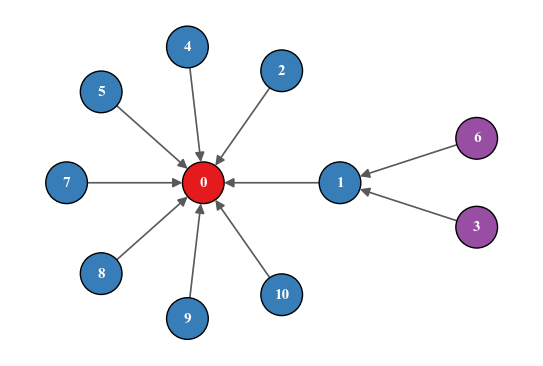

In [8]:
size_by_mass = False
node_size    = 900

nodes = [0] + list(top)
def shown_parent(ind):
    p = tree.ParentID[ind, 0]
    while p not in label:
        p = tree.ParentID[p, 0]
    return p

G = nx.DiGraph()
for ind in nodes:
    G.add_node(label[ind], k=0 if ind == 0 else int(tree.order[ind, 0]), m=tree.mass[ind, 0])
for ind in top:
    G.add_edge(label[ind], label[shown_parent(ind)])

# horizontal layout: host at the centre. k=1 subhalos with their own subhalos (here #1) sit on the
# right, and their subhalos fan out further right. Childless k=1 subhalos fill the left arc.
pos  = {0: np.zeros(2)}
k1   = [n for n in G if G.nodes[n]['k'] == 1]
hubs = [n for n in k1 if G.in_degree(n) > 0]
rest = [n for n in k1 if G.in_degree(n) == 0]

hub_spread  = 20     # deg, half-range of the hub angles around the +x axis
arc         = 55     # deg, the childless k=1 arc runs from +arc to 360 - arc (through the left side)
kid_dx, kid_dy = 1.0, 0.65   # step right and vertical spacing for each deeper level

for a, n in zip(np.radians(np.linspace(-hub_spread, hub_spread, len(hubs)) if len(hubs) > 1 else [0.0]), hubs):
    pos[n] = np.array([np.cos(a), np.sin(a)])
for a, n in zip(np.radians(np.linspace(arc, 360 - arc, len(rest))), rest):
    pos[n] = np.array([np.cos(a), np.sin(a)])

def place_kids(n, dy):
    kids = sorted(G.predecessors(n))
    for i, c in enumerate(kids):
        pos[c] = pos[n] + np.array([kid_dx, dy * (i - (len(kids) - 1) / 2)])
        place_kids(c, dy / 2)
for n in hubs:
    place_kids(n, kid_dy)

colors = [order_color(G.nodes[n]['k']) for n in G]
if size_by_mass:
    lm = np.log10([G.nodes[n]['m'] for n in G])
    sizes = 300 + 1500 * (lm - lm.min()) / np.ptp(lm)
else:
    sizes = np.full(G.number_of_nodes(), node_size)

fig, ax = plt.subplots(figsize=(8, 4.5))
nx.draw_networkx_edges(G, pos, ax=ax, node_size=sizes, edge_color='0.35', width=1.2,
                       arrows=True, arrowstyle='-|>', arrowsize=14)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sizes, node_color=colors, edgecolors='k', linewidths=1)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=11, font_color='w', font_weight='bold',
                        font_family=plt.rcParams['font.family'])
ax.set_aspect('equal'); ax.axis('off'); ax.margins(0.08)

handles = [Line2D([], [], marker='o', ls='', ms=10, mfc=order_color(k), mec='k', label=ORDER_NAME[k])
           for k in sorted({G.nodes[n]['k'] for n in G})]
# ax.legend(handles=handles, loc='upper right', fontsize=10, frameon=False)

fig.savefig(f'{figdir}fig3_z0_graph.pdf', bbox_inches='tight')
plt.show()